In [1]:
import math
import numpy as np
import torch
from torch import nn
from d2l import torch as d2l

In [7]:
max_degree = 20
n_train, n_test = 100, 100
true_w = np.zeros(max_degree)
true_w[0:4] = np.array([5, 1.2, -3.4, 5.6])

features = np.random.normal(size=(n_train+n_test, 1))
np.random.shuffle(features)
ploy_features = np.power(features, np.arange(max_degree).reshape(1,-1))
for i in range(max_degree):
    ploy_features[:,i] /=math.gamma(i+1)
labels = np.dot(ploy_features, true_w)
labels += np.random.normal(scale=0.1, size=labels.shape) 


In [8]:
true_w, features, ploy_features, labels = [torch.tensor(x, dtype=torch.float32) for x in [true_w, features, ploy_features, labels]]

In [9]:
features[:2], ploy_features[:2, :], labels[:2]

(tensor([[-0.3308],
         [ 1.2046]]),
 tensor([[ 1.0000e+00, -3.3082e-01,  5.4721e-02, -6.0343e-03,  4.9907e-04,
          -3.3020e-05,  1.8206e-06, -8.6043e-08,  3.5581e-09, -1.3079e-10,
           4.3267e-12, -1.3012e-13,  3.5873e-15, -9.1289e-17,  2.1572e-18,
          -4.7575e-20,  9.8368e-22, -1.9142e-23,  3.5182e-25, -6.1257e-27],
         [ 1.0000e+00,  1.2046e+00,  7.2550e-01,  2.9131e-01,  8.7725e-02,
           2.1134e-02,  4.2430e-03,  7.3014e-04,  1.0994e-04,  1.4714e-05,
           1.7724e-06,  1.9409e-07,  1.9483e-08,  1.8053e-09,  1.5533e-10,
           1.2474e-11,  9.3911e-13,  6.6543e-14,  4.4531e-15,  2.8232e-16]]),
 tensor([4.4568, 5.7591]))

In [11]:
from d2l.torch import Accumulator
def evalution_loss(net, data_iter, loss):
    metrics = Accumulator(2)
    for X, y in data_iter:
        out = net(X)
        y = y.reshape(out.shape)
        l = loss(out, y)
        metrics.add(l.sum(), l.numel())
    return metrics[0] / metrics[1] 

In [12]:
def train(train_features, test_features, train_labels, test_lables, num_epochs=400):
    loss = nn.MSELoss(reduction='none')
    input_shape = train_features.shape[-1]
    net = nn.Sequential(nn.Linear(input_shape, 1, bias=False))
    batch_size = min(10, train_labels.shape[0])
    train_iter = d2l.load_array((train_features, train_labels.reshape(-1,1)), batch_size)
    test_iter = d2l.load_array((test_features, test_lables.reshape(-1,1)), batch_size, is_train=False)
    trainer = torch.optim.SGD(net.parameters(), lr=0.01)
    animator = d2l.Animator(xlabel='epoch', ylabel='loss', yscale='log',
                            xlim=[1, num_epochs], ylim=[1e-3, 1e2],
                            legend=['train', 'test'])
    for epoch in range(num_epochs):
        d2l.train_epoch_ch3(net, train_iter, loss, trainer)
        if epoch==0 or epoch%20 == 0:
            animator.add(epoch+1, (evalution_loss(net, train_iter, loss), evalution_loss(net, test_iter, loss)))
    print("weight: ", net[0].weight.data.numpy())


weight:  [[ 4.987946   1.2102412 -3.402208   5.572174 ]]


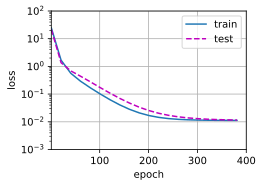

In [14]:
train(ploy_features[:n_train,:4], ploy_features[n_train:, :4],labels[:n_train], labels[n_train:])

weight:  [[3.5107372 3.35482  ]]


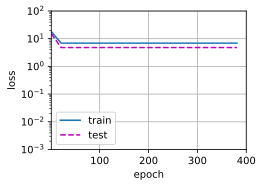

In [15]:
train(ploy_features[:n_train,:2], ploy_features[n_train:, :2],labels[:n_train], labels[n_train:])

weight:  [[ 4.9591675   1.2548459  -3.2495599   5.228858   -0.40526116  1.1731801
   0.24758238  0.14962584 -0.14045922 -0.0555064  -0.07196397  0.15438242
  -0.11164831  0.02198284 -0.01101923  0.18651527  0.08048582  0.0594911
  -0.17775351 -0.1404491 ]]


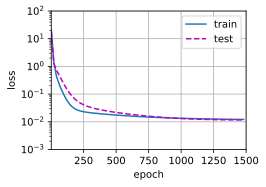

In [17]:
train(ploy_features[:n_train,:], ploy_features[n_train:, :],labels[:n_train], labels[n_train:], num_epochs=1500)

Ran command: `python3 -c "
import json
with open('/Users/songchao/WorkSpace/PythonProject/DeepLearn/pytorch/chapter_multilayer-perceptrons/underfit-overfit.ipynb') as f:
    nb = json.load(f)
for i, cell in enumerate(nb['cells']):
    cell_type = cell['cell_type']
    source = ''.join(cell['source'])
    print(f'=== Cell {i} ({cell_type}) ===')
    if cell_type == 'markdown':
        print(source[:300] + ('...' if len(source) > 300 else ''))
    else:
        print(source[:200] + ('...' if len(source) > 200 else ''))
"`
Ran command: `python3 -c "
import json
with open('/Users/songchao/WorkSpace/PythonProject/DeepLearn/pytorch/chapter_multilayer-perceptrons/underfit-overfit.ipynb') as f:
    nb = json.load(f)
print('--- Cell 0 ---')
print(''.join(nb['cells'][0]['source']))
print('--- Cell 17 ---')
print(''.join(nb['cells'][17]['source']))
"`

[underfit-overfit.ipynb](file:///Users/songchao/WorkSpace/PythonProject/DeepLearn/pytorch/chapter_multilayer-perceptrons/underfit-overfit.ipynb) 是《动手学深度学习》多层感知机章节中讲解**模型选择、欠拟合与过拟合**的核心实验教程。

该 Notebook 从**理论认知**、**概念辨析**到**代码对照实验**，完整呈现了模型复杂度与泛化能力之间的关系。内容总结如下：

---

### 一、 核心概念与理论基础

1. **泛化与记忆（Generalization vs. Memorization）**
   * **训练误差（Training Error）**：模型在训练数据集上表现出的误差。
   * **泛化误差（Generalization Error）**：模型从相同分布中抽取无限多新数据时的预期误差。
   * 机器学习的核心目标是寻找能够**泛化**的通用模式，而非仅“死记硬背”训练样本。

2. **数据划分与模型选择（Model Selection）**
   * **训练集（Training Set）**：用于参数更新与学习。
   * **验证集（Validation Set）**：用于调整超参数与选择最优模型架构（严禁直接拿测试集调参，否则会导致对测试集的过拟合）。
   * **测试集（Test Set）**：用于最终无偏评估模型性能，原则上仅在最后使用一次。
   * **K 折交叉验证（K-Fold Cross-Validation）**：在训练样本有限时，将数据切分为 K 份，轮流用 K-1 份训练、1 份验证并求平均，以充分利用小样本数据评估泛化误差。

3. **影响模型泛化的三大因素**
   * **可调整参数数量（自由度）**：参数越多，模型容量越大，越容易过拟合。
   * **参数取值范围**：权重值波动范围过大时更容易出现过拟合。
   * **训练样本数量**：样本量越少，模型越容易被噪声带偏；样本量越充裕，泛化越稳健。

4. **欠拟合 vs. 过拟合**
   * **欠拟合（Underfitting）**：模型容量过小或表达力不足，导致**训练误差和验证误差都居高不下**，且二者差距较小。
   * **过拟合（Overfitting）**：模型过于复杂或样本不足，**训练误差极低但验证/测试误差显著升高**（泛化差距巨大）。

---

### 二、 代码实验设计（多项式回归）

Notebook 通过人工合成三阶多项式数据集，设计了 3 组对照实验，直观展示了欠拟合、正常拟合与过拟合的真实表现。

#### 1. 数据集生成
生成三阶多项式标签，并引入均值为 0、标准差为 0.1 的高斯噪声：

```text
真实数据生成机制：
  y = 5 + 1.2·x - 3.4·(x² / 2!) + 5.6·(x³ / 3!) + ε
  其中 ε ~ N(0, 0.1²)
```

> **技巧说明**：特征采用 `x^i / i!`（分母为阶乘项，由 Gamma 函数实现）进行特征缩放，避免当多项式阶数 `i` 较大时出现数值爆炸或梯度过大。

#### 2. 训练框架与评估函数
* `evaluate_loss`：计算模型在指定数据集上的均方误差（MSE Loss）。
* `train`：定义单层全连接网络（`nn.Linear(input_shape, 1, bias=False)`，因特征矩阵第 0 列全为 1，自带常数项偏移），采用 SGD 进行优化，并利用动画器实时绘制训练损失与测试损失曲线。

---

### 三、 三组实验与拟合现象对比

| 实验组别 | 选取特征维度 | 模型容量与数据匹配度 | 训练现象与结论 |
| :--- | :--- | :--- | :--- |
| **三阶多项式拟合<br>(正常拟合)** | 前 4 维<br>`(1, x, x²/2!, x³/3!)` | **匹配**：模型阶数与真实生成机制完全一致 | 训练损失与测试损失**均大幅下降并平稳收敛**，学到的权重非常接近真实参数 `[5, 1.2, -3.4, 5.6]`。 |
| **线性函数拟合<br>(欠拟合)** | 前 2 维<br>`(1, x)` | **不足**：线性模型无法表达非线性曲率 | 训练损失和测试损失在训练初期迅速停滞，**最终误差均处于较高水平**，说明模型无法拟合非线性规律。 |
| **高阶多项式拟合<br>(过拟合)** | 全部 20 维特征<br>(训练样本仅 100 个) | **过度**：自由度远超数据量，容纳过多高阶冗余自由度 | 模型为了契合少量数据中的随机噪声，**训练损失被压得极低，但测试损失严重飙升**，泛化表现极差。 |

---

### 四、 本节核心结论与后续引申

1. **核心认知**：
   * 训练误差的降低并不等同于泛化误差的减小。
   * 最佳模型需要在**模型复杂度**与**可用样本规模**之间取得良好平衡。
2. **后续引申**：
   * 当实际任务必须使用复杂网络时，需借助**正则化技术**抑制过拟合，后续章节顺理成章引入**权重衰减（L2 正则化）**与 **暂退法（Dropout）**。

Ran command: `python3 -c "
import json
try:
    with open('/Users/songchao/WorkSpace/PythonProject/DeepLearn/mypytorch/2.4-underfit-overfit.ipynb') as f:
        nb = json.load(f)
    print('mypytorch cells:', len(nb['cells']))
    for i, c in enumerate(nb['cells']):
        if '练习' in ''.join(c['source']):
            print(f'Found 练习 at cell {i}')
except Exception as e:
    print('Error:', e)
"`
Ran command: `python3 -c "
import json
with open('/Users/songchao/WorkSpace/PythonProject/DeepLearn/mypytorch/2.4-underfit-overfit.ipynb') as f:
    nb = json.load(f)
for i, c in enumerate(nb['cells']):
    print(f'=== Cell {i} ({c[\"cell_type\"]}) ===')
    print(''.join(c['source'])[:200])
"`

以下是针对 [underfit-overfit.ipynb](file:///Users/songchao/WorkSpace/PythonProject/DeepLearn/pytorch/chapter_multilayer-perceptrons/underfit-overfit.ipynb) 课后 4 道练习题的详细分析与解答：

---

### 练习 1：这个多项式回归问题可以准确地解出吗？提示：使用线性代数。

#### 解答：
需要从**数学解析解**与**真实参数/标签恢复**两个层面来辩证看待：

1. **从最小二乘数学解析解的角度：可以准确求出闭式解（Closed-form Solution）**
   * 多项式回归在特征转换后，本质上是关于参数 `w` 的多元线性回归：
     ```text
     X·w ≈ y
     ```
   * 只要样本特征矩阵 `X` 是列满秩的（即训练样本数 `n >= 特征维度 d`，且样本特征线性无关），根据正规方程（Normal Equation），经验损失最小化的解析解可由最小二乘法直接得到：
     ```text
     w* = (X^T · X)^(-1) · X^T · y
     ```
   * 即使 `X^T · X` 奇异不可逆，也可以借助 Moore-Penrose 伪逆 `X^+ · y` 或引入岭正则化（Ridge Regression）求得全局最优解，无需依赖随机梯度下降迭代逼近。

2. **从“完全消除误差”或“无偏差恢复真实函数”的角度：无法做到 100% 准确**
   * **不可约噪声存在**：数据生成公式中带有真实噪声 `ε ~ N(0, 0.1²)`。该随机扰动属于不可约误差（Bayes Error）。
   * 即使我们拥有闭式解，得到的也是有限样本下的统计估计量 `w*`；由于有限样本中噪声的存在，估计出来的权重向量与真实的 `[5, 1.2, -3.4, 5.6]` 会存在细微偏差，且新样本的预测值与真实标签之间始终存在噪声底噪。

---

### 练习 2：考虑多项式的模型选择。

#### 1. 绘制训练损失与模型复杂度（多项式阶数）的关系图。观察到了什么？需要多少阶的多项式才能将训练损失减少到 0？
* **现象与规律**：
  * **1 ~ 3 阶**：随着阶数增加，训练损失呈现指数级快速下降。这是因为 1、2 阶模型处于欠拟合状态，提升阶数能够快速捕获数据中的 3 阶非线性规律。
  * **3 阶以上**：训练损失会继续缓慢降低，但下降幅度逐渐放缓。
* **阶数要求**：
  * **需要 `n - 1` 阶（或包含常数项共 `n` 个自由参数）**才能将训练损失降为 0。
  * **原理**：根据线性代数中的拉格朗日插值多项式（Lagrange Interpolation）与范德蒙德矩阵（Vandermonde Matrix）理论，对于 `n` 个互不相同的样本点，总存在且仅存在一个 `n - 1` 阶多项式能够**精准穿过所有样本点**。本实验中若训练集有 `n = 100` 个样本，当阶数达到 99 阶时，模型即可实现对训练集的完美无误差插值（此时训练损失为 0，但发生极度严重的过拟合）。

#### 2. 在这种情况下绘制测试的损失图。
* **现象与规律**：
  * 测试损失呈现经典的 **U 型曲线**：
    * **阶数 < 3**：欠拟合区间，模型偏差（Bias）大，测试损失很高；
    * **阶数 = 3**：达到最佳平衡点，测试损失达到全域最低值；
    * **阶数 > 3**：进入过拟合区间，模型方差（Variance）急剧上升，测试损失开始快速抬升；当阶数进一步增大到接近样本数量时，测试损失会呈现指数级爆炸。

#### 3. 生成同样的图，作为数据量的函数（即固定模型复杂度，以训练样本量 n 为自变量）。
* **现象与规律（学习曲线 Learning Curve）**：
  * 若固定一个容量较高的复杂模型（如 10 阶或 20 阶多项式）：
    * **样本量 `n` 极少时**：训练损失极低（因为复杂模型能轻易记住极少数点），但测试损失极高，泛化差距（Generalization Gap）巨大；
    * **随着样本量 `n` 逐步扩大**：训练损失会有所上升（越来越难以用固定容量去完美拟合所有带噪样本），而测试损失则快速下降，二者差距逐渐收窄并收敛到一个渐近线（即模型的最佳泛化能力上限）。

---

### 练习 3：如果不对多项式特征 `x^i` 进行标准化（`1/i!`），会发生什么事情？能用其他方法解决这个问题吗？

#### 1. 会发生的问题：
* **数值极度不平衡与梯度爆炸/消失**：
  * 当 `|x| > 1` 时，随着阶数增大，高阶项会急剧膨胀（如 `2^20 ≈ 10^6`）；而当 `|x| < 1` 时，高阶项则快速趋近于 0。
  * 这导致不同特征维度的量纲相差十几个数量级。
* **矩阵条件数严重恶化（Ill-conditioned Problem）**：
  * 原始范德蒙德矩阵的条件数随阶数指数级暴涨。
  * 损失函数的等高线会变成极其狭长扁平的椭圆，导致梯度更新剧烈振荡，使用梯度下降法时学习率极难调校，极易触发数值溢出（`NaN`/`Inf`）或收敛极度迟缓。

#### 2. 其他替代解决办法：
1. **特征归一化 / 标准化（Standardization）**：
   * 计算每一列特征的均值与标准差，转化为 Z-Score：`x_norm = (x - μ) / σ`，将所有维度的尺度约束在统一范围内。
2. **使用正交多项式基（Orthogonal Polynomials）**：
   * 避免使用基底 `{1, x, x², ...}`，改用**勒让德多项式（Legendre Polynomials）**或**切比雪夫多项式（Chebyshev Polynomials）**构建特征。这类正交基天然具备出色的数值稳定性，能从根源上消除范德蒙德矩阵的病态性。
3. **自适应学习率优化器与梯度裁剪**：
   * 使用 Adam 等具有按维度缩放自适应学习率的优化器，并辅以梯度裁剪（Gradient Clipping）防止梯度过大。

---

### 练习 4：泛化误差可能为零吗？

#### 解答：
**在绝大多数现实的机器学习任务中，泛化误差不可能为零。**

* **核心原因（不可约误差 Bayes Error）**：
  * 统计学习理论中，泛化误差通常可分解为三部分：
    ```text
    泛化误差 = 偏差² (Bias²) + 方差 (Variance) + 不可约误差 (Irreducible Error)
    ```
  * 数据采集环境必然存在不可观测的潜在变量、测量噪声或随机干扰（如本节设定的高斯噪声 `ε ~ N(0, 0.1²)`）。由于噪声本身的随机性，即使模型找到了完全正确的真实映射关系 `f(x)`，新样本的标签依然带有不可预测的方差 `σ²`，因此泛化误差至少大于等于该噪声方差（`σ² = 0.01 > 0`）。

* **理论上为零的极端特例（反例）**：
  只有同时满足以下极其苛刻的理想条件时才可能为 0：
  1. 数据生成机制完全是**确定性无噪声的**（`ε ≡ 0`）；
  2. 模型的假设空间能够**无偏差地完美覆盖**真实函数；
  3. 样本数据充分，且算法找到了理论上的真实目标函数（例如在离散有限状态集合上的确定性逻辑映射或无噪声查表任务）。